# Обнаружение резких изменений

**Идея:** прогноз на 1 месяц вперёд даёт ожидаемые расходы. Если факт сильно отличается от прогноза,
а у остальных (в том же регионе) этого нет, у территории что-то произошло. Это «шок».

**План:**
1. Остатки прогноза (факт − прогноз) по территориям и месяцам.
2. Очистка остатков от общего движения региона и от «обычного уровня» ошибки территории.
3. Три метода поиска скачка: z-score, CUSUM, поиск точки смены среднего.
4. Сравнение методов на искусственных скачках (настоящей разметки шоков у нас нет).
5. Взгляд на реальные события (повышения ключевой ставки).

Остатки считаются только по месяцам с 13-го по 24-й: для seasonal naive нужен год истории,
поэтому у каждой территории всего ~12 точек. Это ограничение влияет на все решения ниже.

In [13]:
%load_ext autoreload
%autoreload 2
from forecasting import *
import matplotlib.pyplot as plt

df_general = pd.read_parquet('../data/df_general.parquet')
dates_all = pd.to_datetime(np.sort(df_general['date'].unique()))
holiday = df_general.groupby('date')['holiday_count'].first()
SHOCK_TARGETS = list(dates_all[12:]) # месяцы 13..24

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Шаг 1. Остатки прогноза

Для каждого месяца 13–24 делаю прогноз итоговой моделью на 1 месяц вперёд (только по данным до этого месяца)
и считаю относительную ошибку `e = (факт − прогноз) / прогноз`. Относительная, чтобы большие и малые
территории были сравнимы.

Затем `e` превращается в `z`: из `e` вычитается движение региона за этот месяц (медиана по региону,
а если в регионе меньше 5 территорий, то по стране), и результат делится на типичный разброс (MAD, устойчивый к выбросам).

In [14]:
def get_residuals(df, targets=SHOCK_TARGETS):
    rows = []
    for tgt in targets:
        cutoff = tgt - pd.DateOffset(months=1)
        train = df[df['date'] <= cutoff]
        pred = final_forecast(train, 1, tgt, holiday=holiday).rename(columns={TARGET: 'pred'})
        act = df[df['date'] == tgt][['territory_id', TARGET]].rename(columns={TARGET: 'y'})
        m = act.merge(pred, on='territory_id')
        m['target'] = tgt
        rows.append(m)
    R = pd.concat(rows, ignore_index=True)
    R['e'] = (R['y'] - R['pred']) / R['pred']

    reg = df[['territory_id', 'region_name']].drop_duplicates('territory_id')
    R = R.merge(reg, on='territory_id', how='left')

    nat_med = R.groupby('target')['e'].transform('median')
    nat_mad = R.groupby('target')['e'].transform(lambda s: 1.4826 * (s - s.median()).abs().median())
    reg_med = R.groupby(['target', 'region_name'])['e'].transform('median')
    reg_n = R.groupby(['target', 'region_name'])['e'].transform('count')

    center = np.where(reg_n >= 5, reg_med, nat_med)
    R['z'] = (R['e'] - center) / nat_mad
    return R

In [15]:
R = get_residuals(df_general)
R['big'] = R['z'].abs() > 3

print(R['e'].describe().round(3))
print('\nДоля |z|>3 по месяцам:')
print(R.groupby('target')['big'].mean().round(3))
print('\nТоп-5 регионов по доле |z|>3:')
print(R.groupby('region_name')['big'].mean().sort_values().tail(5).round(3))

count    24957.000
mean         0.004
std          0.052
min         -0.393
25%         -0.025
50%          0.005
75%          0.033
max          0.305
Name: e, dtype: float64

Доля |z|>3 по месяцам:
target
2024-01-01    0.004
2024-02-01    0.001
2024-03-01    0.000
2024-04-01    0.030
2024-05-01    0.029
2024-06-01    0.026
2024-07-01    0.032
2024-08-01    0.036
2024-09-01    0.039
2024-10-01    0.031
2024-11-01    0.030
2024-12-01    0.023
Name: big, dtype: float64

Топ-5 регионов по доле |z|>3:
region_name
Карачаево-Черкесская Республика    0.092
Республика Калмыкия                0.123
Кабардино-Балкарская Республика    0.124
Республика Тыва                    0.188
Чеченская Республика               0.571
Name: big, dtype: float64


### Что показала диагностика остатков (и что пришлось исправить)

Ошибка прогноза в среднем около нуля, типичная величина около 5% (в духе WAPE ≈ 3% из бэктеста).
Но первая версия очистки (вычитание медианы по стране) дала странную картину:

- в январе–марте |z|>3 у 0,1–0,4% территорий, а с апреля у 3–5%;
- «большими» много месяцев подряд были одни и те же территории, и сидели они в нескольких регионах:
  Чеченская Республика (68% наблюдений), Дагестан (54%), Тыва, Сахалин, Магадан (22–25%).

**Причина:** seasonal naive умножает прошлогоднее значение на *один общий рост по стране*. Там, где
рост отличается от общего, прогноз систематически мимо, и остаток «висит» на одной стороне много месяцев.
Метод принял бы это за шоки, хотя это особенность региона.

**Что сделала:**
1. Вычитаю движение *региона*, а не страны (так в этой ячейке).
2. Дальше (следующая ячейка) вычитаю собственную медиану остатков территории и делю на разброс региона:
   Чечня и остальные ушли с вершины списка (теперь верхушка — Сахалин 12%, Камчатка 11%).

**Побочный эффект:** после второй очистки общая доля |z|>3 стала выше (3–8%) и к концу года растёт.
Причину не выясняла. Это не мешает сравнению методов, потому что порог каждого метода подбирается
по доле ложных тревог, а не фиксируется на 3.

In [19]:
R = get_residuals(df_general)
R['big'] = R['z'].abs() > 3

print('Доля |z|>3 по месяцам:')
print(R.groupby('target')['big'].mean().round(3))

cnt = R.groupby('territory_id')['big'].sum()
print('\nСколько территорий были "большими" N месяцев:')
print(cnt.value_counts().sort_index())

print('\nТоп-5 регионов:')
print(R.groupby('region_name')['big'].mean().sort_values().tail(5).round(3))

Z = R.pivot(index='territory_id', columns='target', values='z')

Доля |z|>3 по месяцам:
target
2024-01-01    0.004
2024-02-01    0.001
2024-03-01    0.000
2024-04-01    0.030
2024-05-01    0.029
2024-06-01    0.026
2024-07-01    0.032
2024-08-01    0.036
2024-09-01    0.039
2024-10-01    0.031
2024-11-01    0.030
2024-12-01    0.023
Name: big, dtype: float64

Сколько территорий были "большими" N месяцев:
big
0    1821
1     164
2      54
3      40
4      14
5      11
6      10
7       1
8       1
9       1
Name: count, dtype: int64

Топ-5 регионов:
region_name
Карачаево-Черкесская Республика    0.092
Республика Калмыкия                0.123
Кабардино-Балкарская Республика    0.124
Республика Тыва                    0.188
Чеченская Республика               0.571
Name: big, dtype: float64


In [16]:
def clean_Z(R):
    Z = R.pivot(index='territory_id', columns='target', values='z')
    # убираем "обычный уровень" каждой территории
    Zc = Z.sub(Z.median(axis=1), axis=0)
    # делим на типичный разброс региона (в малых регионах — общий)
    reg = R.drop_duplicates('territory_id').set_index('territory_id')['region_name']
    long = Zc.stack().rename('v').reset_index()
    long['region_name'] = long['territory_id'].map(reg)

    def mad(s):
        return 1.4826 * (s - s.median()).abs().median()

    global_mad = mad(long['v'])
    reg_mad = long.groupby('region_name')['v'].apply(mad)
    reg_n = reg.groupby(reg).size()
    reg_mad[reg_n[reg_n < 5].index.intersection(reg_mad.index)] = global_mad

    scale = reg.map(reg_mad).reindex(Zc.index).fillna(global_mad)
    return Zc.div(scale, axis=0)

Zc = clean_Z(R)

big = Zc.abs() > 3
print('Доля |z|>3 по месяцам:')
print(big.mean().round(3))
print('\nСколько территорий были "большими" N месяцев:')
print(big.sum(axis=1).value_counts().sort_index())

reg = R.drop_duplicates('territory_id').set_index('territory_id')['region_name']
print('\nТоп-5 регионов:')
print(big.mean(axis=1).groupby(reg.reindex(big.index)).mean().sort_values().tail(5).round(3))

Доля |z|>3 по месяцам:
target
2024-01-01    0.030
2024-02-01    0.037
2024-03-01    0.026
2024-04-01    0.049
2024-05-01    0.039
2024-06-01    0.032
2024-07-01    0.036
2024-08-01    0.051
2024-09-01    0.067
2024-10-01    0.067
2024-11-01    0.070
2024-12-01    0.079
dtype: float64

Сколько территорий были "большими" N месяцев:
0     1498
1      327
2      137
3       74
4       42
5       13
6       17
7        3
8        3
10       3
Name: count, dtype: int64

Топ-5 регионов:
region_name
Тамбовская область     0.077
Республика Калмыкия    0.083
Московская область     0.091
Камчатский край        0.114
Сахалинская область    0.123
dtype: float64


### Чем плоха такая очистка

Вычитание собственной медианы убирает «обычный уровень» ошибки территории. Побочный эффект:
если сдвиг держится больше половины из 12 месяцев, он становится «обычным уровнем» и пропадает.
Метод видит только недавние изменения. На 12 точках отличить давний долгий шок
от постоянной особенности территории нельзя.

## Шаги 2–3. Три метода и честное сравнение

Каждый метод даёт для каждой территории и месяца «оценку тревоги»:
- **z-score:** разовое превышение `|z|`. Быстро ловит резкие скачки.
- **CUSUM:** копит небольшие отклонения в одну сторону. Лучше ловит устойчивые сдвиги, но позже.
- **Поиск точки смены среднего:** на каждом месяце ищет лучшее деление ряда на две части и смотрит,
  насколько отличаются средние (критерий как у PELT для одной точки, написан сама, `ruptures` не использовался).

**Как сравниваю:** настоящей разметки шоков нет, поэтому вставляю искусственные: у случайных 10% территорий
с августа 2024 расходы умножаются на 1 ± размер (+/−10%, 20%, 30%). Остатки пересчитываются на изменённых данных.
Порог каждого метода подбирается так, чтобы у нетронутых территорий было **5% ложных тревог**
(иначе выиграл бы метод с самым низким порогом). Скачок начинается в августе, чтобы он длился меньше
половины месяцев и не «съедался» очисткой.
**Метрики:** доля найденных скачков и задержка (в месяцах от начала скачка до первой тревоги).

In [17]:
def score_zscore(Z):
    """Разовое превышение: просто |z|"""
    return np.abs(np.nan_to_num(Z.values))

def score_cusum(Z, k=0.5):
    """CUSUM: копит отклонения в одну сторону, k - допустимый шум"""
    A = np.nan_to_num(Z.values); n, T = A.shape
    pos = np.zeros(n); neg = np.zeros(n); S = np.zeros_like(A)
    for t in range(T):
        pos = np.maximum(0, pos + A[:, t] - k)
        neg = np.maximum(0, neg - A[:, t] - k)
        S[:, t] = np.maximum(pos, neg)
    return S

def score_changepoint(Z, min_seg=2):
    """Поиск точки смены среднего: на каждом месяце берём лучшее деление ряда на 2 части
    и смотрим, насколько средние различаются"""
    A = np.nan_to_num(Z.values); n, T = A.shape
    S = np.zeros_like(A)
    for t in range(2 * min_seg - 1, T):
        w = A[:, :t + 1]; m = t + 1
        best = np.zeros(n)
        for k in range(min_seg, m - min_seg + 1):
            diff = w[:, :k].mean(axis=1) - w[:, k:].mean(axis=1)
            best = np.maximum(best, k * (m - k) / m * diff ** 2)
        S[:, t] = best
    return S

METHODS = {'z-score': score_zscore, 'CUSUM': score_cusum, 'change-point': score_changepoint}

# порог подбирается так, чтобы у нормальных территорий было 5% ложных тревог
def evaluate(S, shocked_mask, start_col, fa_rate=0.05):
    thr = np.quantile(S[~shocked_mask].max(axis=1), 1 - fa_rate)
    alarm = S[shocked_mask][:, start_col:] > thr # тревоги с момента скачка
    found = alarm.any(axis=1)
    delay = alarm.argmax(axis=1)[found]
    return {'найдено': found.mean(),
            'задержка_мес': delay.mean() if found.any() else np.nan}

# вставка искусственных скачков
def inject(df, ids, signs, start_date, size):
    df2 = df.copy()
    df2[TARGET] = df2[TARGET].astype(float)
    factor = df2['territory_id'].map(lambda t: 1 + size * signs[t] if t in signs else 1.0)
    after = (df2['date'] >= start_date) & df2['territory_id'].isin(ids)
    df2.loc[after, TARGET] = df2.loc[after, TARGET] * factor[after]
    return df2

rng = np.random.default_rng(0)
shock_ids = rng.choice(Zc.index.values, size=int(0.10 * len(Zc)), replace=False) # 10% территорий
signs = {t: rng.choice([-1, 1]) for t in shock_ids} # вверх или вниз
START_COL = 7 # 8-й месяц из 12 = август 2024
start_date = SHOCK_TARGETS[START_COL]

results = []
for size in [0.10, 0.20, 0.30]:
    df_mod = inject(df_general, shock_ids, signs, start_date, size)
    Zc_mod = clean_Z(get_residuals(df_mod)) # остатки пересчитываем на изменённых данных
    mask = Zc_mod.index.isin(shock_ids)
    for name, f in METHODS.items():
        r = evaluate(f(Zc_mod), mask, START_COL)
        results.append({'размер скачка': f'{size:.0%}', 'метод': name, **r})
    print('готово:', size)

res_shocks = pd.DataFrame(results)
print(res_shocks.pivot(index='метод', columns='размер скачка', values='найдено').round(2))
print(res_shocks.pivot(index='метод', columns='размер скачка', values='задержка_мес').round(2))

готово: 0.1
готово: 0.2
готово: 0.3
размер скачка   10%   20%   30%
метод                          
CUSUM          0.64  0.97  0.99
change-point   0.64  0.98  0.99
z-score        0.40  0.94  0.99
размер скачка   10%   20%   30%
метод                          
CUSUM          2.05  0.88  0.18
change-point   1.46  0.53  0.11
z-score        0.68  0.09  0.00


### Результаты

| Доля найденных | 10% | 20% | 30% |
|---|---|---|---|
| z-score | 0,40 | 0,94 | 0,99 |
| CUSUM | 0,64 | 0,97 | 0,99 |
| Поиск точки смены | 0,64 | 0,98 | 0,99 |

| Задержка, мес | 10% | 20% | 30% |
|---|---|---|---|
| z-score | 0,68 | 0,09 | 0,00 |
| CUSUM | 2,05 | 0,88 | 0,18 |
| Поиск точки смены | 1,46 | 0,53 | 0,11 |

**Выводы:**
- Крупные скачки (20–30%) находят все методы, z-score мгновенно.
- Небольшие (10%) z-score пропускает в 60% случаев, а CUSUM и поиск точки смены находят 64%.
- Поиск точки смены лучше CUSUM по скорости при той же полноте.
- Задержка считается только по найденным скачкам, поэтому у z-score на 10% маленькая задержка
  «обманчива»: это среднее по 40% лёгких случаев. Главная метрика — доля найденных.
- **Практический вывод:** основной метод — поиск точки смены; z-score — быстрый детектор крупных скачков.

## Реальные события: ключевая ставка

Повышения ставки в июле (16→18%) и октябре (19→21%) 2024: виден ли эффект в остатках?

            медиана ошибки прогноза  доля |z|>3
target                                         
2024-01-01                   -0.028       0.030
2024-02-01                    0.064       0.037
2024-03-01                    0.004       0.026
2024-04-01                    0.016       0.049
2024-05-01                   -0.017       0.039
2024-06-01                    0.014       0.032
2024-07-01                   -0.014       0.036
2024-08-01                    0.018       0.051
2024-09-01                   -0.002       0.067
2024-10-01                    0.020       0.067
2024-11-01                   -0.023       0.070
2024-12-01                    0.020       0.079


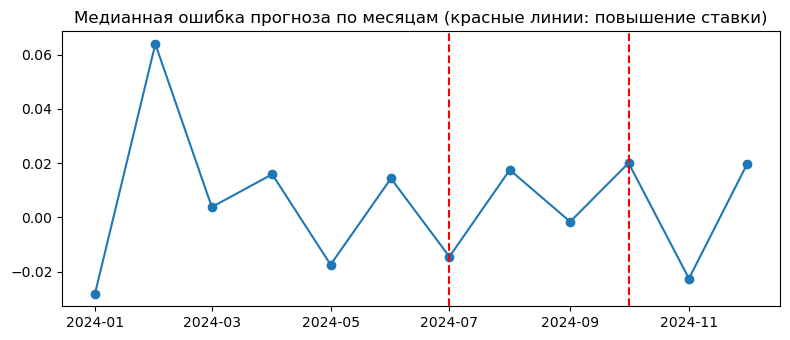

In [18]:
by_month = pd.DataFrame({
    'медиана ошибки прогноза': R.groupby('target')['e'].median(),
    'доля |z|>3': (Zc.abs() > 3).mean(),
})
print(by_month.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(by_month.index, by_month['медиана ошибки прогноза'], marker='o')
for d in ['2024-07-01', '2024-10-01']:
    ax.axvline(pd.Timestamp(d), color='red', ls='--')
ax.set_title('Медианная ошибка прогноза по месяцам (красные линии: повышение ставки)')
plt.tight_layout(); plt.show()

**Результат:** эффекта не видно. Медианная ошибка колеблется в пределах ±2–3% без связи с датами решений,
доля |z|>3 растёт плавно с августа по декабрь. Это ожидаемо: общее движение мы вычитали при очистке,
поэтому эффект, общий для всех территорий, не должен быть виден. Единственный заметный выброс
общей ошибки — февраль 2024 (+6,4%); возможно, календарный эффект високосного года, не проверяла.

## Ограничения

- Всего ~12 точек на территорию, настоящих меток шоков нет.
- Скачки искусственные: один месяц начала (август), один сид, 10% территорий, один знак на территорию.
- Вставка в расходы реалистична только отчасти: seasonal naive опирается на значение «год назад»,
  которое не изменено, поэтому остаток после скачка держится заметным несколько месяцев.
- Давние долгие сдвиги метод не видит (см. выше).
- 5% ложных тревог на территорию за год — много для практики; порог можно ужесточить ценой пропусков.
- Региональные шоки (например, у всей области сразу) очистка вычитает; их можно искать отдельно по медианам регионов.
- Не использованы новости и календарь событий (возможное развитие).